In [1]:
# --- Setup cell (delete this entire cell when merging into semestral_project.ipynb) ---
import json
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# 1. Load exported data (exact variable names from semestral_project.ipynb)
model_spec = json.load(open("exports/model_features.json", encoding="utf-8"))
id_cols, target = model_spec["id_cols"], model_spec["target"]
baseline_features, extended_features = model_spec["baseline_features"], model_spec["extended_features"]

extended_data = pd.read_csv("exports/model_data.csv", parse_dates=["Date"], dtype={"season": str})
baseline_data = extended_data[id_cols + baseline_features + [target]]

# 2. Locked chronological split from Section 5
FINAL_TRAIN_SEASONS = ["2021", "2122", "2223"]
VAL_SEASONS = ["2324"]
TEST_SEASONS = ["2425"]
FINAL_DROP_CLOSED_DOORS = False


def split_by_season(
    df,
    train_seasons=FINAL_TRAIN_SEASONS,
    val_seasons=VAL_SEASONS,
    test_seasons=TEST_SEASONS,
    drop_closed_doors=FINAL_DROP_CLOSED_DOORS,
):
    train = df[df["season"].isin(train_seasons)].copy()
    if drop_closed_doors:
        train = train[train["closed_doors"] == 0].copy()
    val = df[df["season"].isin(val_seasons)].copy()
    test = df[df["season"].isin(test_seasons)].copy()
    assert train["Date"].max() < val["Date"].min(), "Train/val date overlap!"
    assert val["Date"].max() < test["Date"].min(), "Val/test date overlap!"
    assert "2223" in train_seasons, "2223 must remain in train (Elo tuning constraint)."
    return train, val, test


# 3. Shared evaluation and prediction-export helpers from Section 5.2
def evaluate_predictions(df, y_prob, model_name="model", threshold=0.5):
    y_true = df[target].to_numpy()
    y_prob = np.asarray(y_prob, dtype=float)
    y_pred = (y_prob >= threshold).astype(int)
    overall = {
        "model": model_name,
        "matches": len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "log_loss": log_loss(y_true, y_prob, labels=[0, 1]),
        "pred_over_rate": y_pred.mean(),
        "true_over_rate": y_true.mean(),
    }
    rows = []
    for country, idx in df.groupby("country").groups.items():
        pos = df.index.get_indexer(idx)
        yt, yp = y_true[pos], y_prob[pos]
        rows.append({
            "country": country,
            "matches": len(yt),
            "accuracy": accuracy_score(yt, (yp >= threshold).astype(int)),
            "log_loss": log_loss(yt, yp, labels=[0, 1]),
        })
    by_country = pd.DataFrame(rows).sort_values("matches", ascending=False).reset_index(drop=True)
    return overall, by_country


def build_predictions_df(df, prob_dict):
    out = df[["country", "season", "Date", "HomeTeam", "AwayTeam", target]].copy()
    for col_name, probs in prob_dict.items():
        out[col_name] = np.asarray(probs, dtype=float)
    return out


# 4. Shared Logistic Regression pipeline & final Baseline XGBoost from Section 6.1
class QuantileClipper(BaseEstimator, TransformerMixin):
    def __init__(self, lower_q=0.001, upper_q=0.995):
        self.lower_q = lower_q
        self.upper_q = upper_q

    def fit(self, X, y=None):
        X_arr = np.asarray(X, dtype=float)
        self.lower_ = np.nanquantile(X_arr, self.lower_q, axis=0)
        self.upper_ = np.nanquantile(X_arr, self.upper_q, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)


def make_logreg_pipeline(C=0.1, lower_q=0.001, upper_q=0.995):
    return Pipeline([
        ("clip", QuantileClipper(lower_q=lower_q, upper_q=upper_q)),
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=C, max_iter=1000)),
    ])


BASELINE_LR_C = 0.003
BASELINE_XGB_PARAMS = {
    "n_estimators": 253,
    "learning_rate": 0.02,
    "max_depth": 2,
    "min_child_weight": 20,
    "subsample": 0.8,
    "colsample_bytree": 0.4,
    "reg_lambda": 2.0,
    "reg_alpha": 0.0,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "random_state": 42,
    "n_jobs": -1,
}


def make_baseline_xgb():
    return XGBClassifier(**BASELINE_XGB_PARAMS)

## 6.2 Extended models on validation `2324` (A1)

We use the same locked split as the baseline (train `2021–2223`, validation `2324`, test `2425`) and all `88` features (`41` baseline + `47` extended). ID columns and the target are never used as features.

In [2]:
# Split the extended dataset by season (same split as baseline for fair comparison)
train_ext, val_ext, test_ext = split_by_season(
    extended_data,
    train_seasons=FINAL_TRAIN_SEASONS,
    val_seasons=VAL_SEASONS,
    test_seasons=TEST_SEASONS,
    drop_closed_doors=FINAL_DROP_CLOSED_DOORS,
)

# Combine baseline and extended features (should be 88 features total)
all_features = baseline_features + extended_features

# Quick sanity check on shapes and feature list
print(f"Train shape: {train_ext.shape}")
print(f"Validation (2324) shape: {val_ext.shape}")
print(f"Test (2425) shape: {test_ext.shape}")
print(f"Total number of features: {len(all_features)}")

# Make sure no ID columns or the target leaked into the feature list
leaked_cols = set(all_features).intersection(set(id_cols + [target]))
assert len(leaked_cols) == 0, f"Found non-feature columns in all_features: {leaked_cols}"
print("Sanity check passed: no ID columns or target in all_features.")

Train shape: (21728, 96)
Validation (2324) shape: (7245, 96)
Test (2425) shape: (7126, 96)
Total number of features: 88
Sanity check passed: no ID columns or target in all_features.


In [3]:
# Prepare training and validation matrices using all 88 features
X_train, y_train = train_ext[all_features], train_ext[target]
X_val = val_ext[all_features]

# Grid of regularization strengths C to test (smaller C = stronger regularization)
c_values = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]

lr_results = []

for c in c_values:
    # Use the exact same pipeline constructor as in the baseline notebook
    lr_model = make_logreg_pipeline(C=c)
    lr_model.fit(X_train, y_train)

    # Predict probabilities for the positive class (Over 2.5 goals) on validation 2324
    val_probs = lr_model.predict_proba(X_val)[:, 1]

    # evaluate_predictions returns a tuple: (overall metrics, per-country metrics)
    overall, by_country = evaluate_predictions(val_ext, val_probs, model_name=f"Extended LogReg C={c}")
    lr_results.append({"C": c, **overall})

# Display tuning results as a clean table
lr_results_df = pd.DataFrame(lr_results)
display(lr_results_df)

,C,model,matches,accuracy,log_loss,pred_over_rate,true_over_rate
0,0.001,Extended LogReg C=0.001,7245,0.578054,0.673186,0.527260,0.531263
1,0.005,Extended LogReg C=0.005,7245,0.580814,0.672929,0.531677,0.531263
2,0.010,Extended LogReg C=0.01,7245,0.579986,0.672913,0.532781,0.531263
3,0.050,Extended LogReg C=0.05,7245,0.579710,0.672899,0.532505,0.531263
4,0.100,Extended LogReg C=0.1,7245,0.580124,0.672913,0.532643,0.531263
5,0.500,Extended LogReg C=0.5,7245,0.580676,0.672980,0.534300,0.531263
6,1.000,Extended LogReg C=1.0,7245,0.581504,0.672995,0.534300,0.531263
7,5.000,Extended LogReg C=5.0,7245,0.581366,0.673022,0.533333,0.531263
8,10.000,Extended LogReg C=10.0,7245,0.581090,0.673011,0.533609,0.531263


### Extended Logistic Regression – tuning `C`

We used the same `make_logreg_pipeline` as the baseline (quantile clipping → median imputation → scaling → logistic regression) and only tuned the regularization strength `C` on `2324`.

**Selected:** `C = 0.05` – lowest validation log-loss (`0.67290`, accuracy `57.97%`).

- Performance is **very flat** across the grid: log-loss only ranges from `0.67290` to `0.67319` and accuracy from `57.8%` to `58.2%`, so the choice of `C` has little practical effect.
- `C = 1.0` has a slightly higher accuracy (`58.15%`), but the difference of ~`0.2` pp is only about `13` matches out of `7,245`, which is within noise.
- **Log-loss is our main selection metric**, because it rewards good probability estimates and not only correct 0/1 predictions.
- The predicted over-rate (`53.3%`) closely matches the true over-rate (`53.1%`), so the model is not biased towards either class.

In [4]:
# Validation matrices (X_train and y_train are already defined in the LogReg cell)
X_val, y_val = val_ext[all_features], val_ext[target]

# Settings that stay the same in every run (same as the baseline XGBoost)
learning_rate = 0.02
subsample = 0.8
reg_lambda = 2.0

# Small grid of the most important tree parameters
max_depth_values = [2, 3, 4]               # how deep each tree can grow
min_child_weight_values = [20, 50]         # minimum data needed in a leaf (higher = more conservative)
colsample_values = [0.3, 0.5, 0.7]         # share of features each tree can use

xgb_results = []

for md in max_depth_values:
    for mcw in min_child_weight_values:
        for cs in colsample_values:
            # Allow many trees and let early stopping on 2324 find the best number of trees
            # NaN values are left as they are, XGBoost handles missing values on its own
            xgb_model = XGBClassifier(
                n_estimators=3000,
                learning_rate=learning_rate,
                max_depth=md,
                min_child_weight=mcw,
                subsample=subsample,
                colsample_bytree=cs,
                reg_lambda=reg_lambda,
                objective="binary:logistic",
                eval_metric="logloss",
                early_stopping_rounds=100,   # stop if validation log-loss does not improve for 100 trees
                random_state=42,
                n_jobs=-1,
            )
            xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

            # Number of trees at the best validation log-loss
            best_n_trees = xgb_model.best_iteration + 1

            # Predict on 2324 using only the trees up to the best iteration
            val_probs = xgb_model.predict_proba(X_val, iteration_range=(0, best_n_trees))[:, 1]

            overall, by_country = evaluate_predictions(val_ext, val_probs, model_name="Extended XGBoost")
            xgb_results.append({
                "max_depth": md,
                "min_child_weight": mcw,
                "colsample_bytree": cs,
                "n_estimators": best_n_trees,
                "accuracy": overall["accuracy"],
                "log_loss": overall["log_loss"],
                "pred_over_rate": overall["pred_over_rate"],
            })

            # Progress print so we can see the loop is still running
            print(f"done: max_depth={md}, min_child_weight={mcw}, colsample={cs} -> "
                  f"{best_n_trees} trees, log-loss={overall['log_loss']:.5f}")

# Sort by validation log-loss (our main selection metric) and show the best settings
xgb_results_df = pd.DataFrame(xgb_results).sort_values("log_loss").reset_index(drop=True)
display(xgb_results_df.head(10))

done: max_depth=2, min_child_weight=20, colsample=0.3 -> 316 trees, log-loss=0.67374
done: max_depth=2, min_child_weight=20, colsample=0.5 -> 250 trees, log-loss=0.67377
done: max_depth=2, min_child_weight=20, colsample=0.7 -> 348 trees, log-loss=0.67372
done: max_depth=2, min_child_weight=50, colsample=0.3 -> 256 trees, log-loss=0.67394
done: max_depth=2, min_child_weight=50, colsample=0.5 -> 256 trees, log-loss=0.67382
done: max_depth=2, min_child_weight=50, colsample=0.7 -> 312 trees, log-loss=0.67385
done: max_depth=3, min_child_weight=20, colsample=0.3 -> 252 trees, log-loss=0.67396
done: max_depth=3, min_child_weight=20, colsample=0.5 -> 231 trees, log-loss=0.67392
done: max_depth=3, min_child_weight=20, colsample=0.7 -> 243 trees, log-loss=0.67389
done: max_depth=3, min_child_weight=50, colsample=0.3 -> 250 trees, log-loss=0.67407
done: max_depth=3, min_child_weight=50, colsample=0.5 -> 237 trees, log-loss=0.67400
done: max_depth=3, min_child_weight=50, colsample=0.7 -> 243 tree

,max_depth,min_child_weight,colsample_bytree,n_estimators,accuracy,log_loss,pred_over_rate
0,2,20,0.7,348,0.578192,0.673717,0.523257
1,2,20,0.3,316,0.576950,0.673737,0.519807
2,2,20,0.5,250,0.578744,0.673766,0.514976
3,2,50,0.5,256,0.578330,0.673818,0.514286
4,2,50,0.7,312,0.579434,0.673847,0.520359
5,3,20,0.7,243,0.580400,0.673888,0.522429
6,3,20,0.5,231,0.578330,0.673925,0.518703
7,2,50,0.3,256,0.577226,0.673942,0.515390
8,3,20,0.3,252,0.578606,0.673955,0.523119
9,3,50,0.5,237,0.578330,0.673997,0.518979


### Extended XGBoost – tuning on validation `2324`

We tuned the Extended XGBoost over a small grid of `max_depth` ∈ {`2`, `3`, `4`}, `min_child_weight` ∈ {`20`, `50`} and `colsample_bytree` ∈ {`0.3`, `0.5`, `0.7`}. The other settings were kept the same as in the baseline (`learning_rate=0.02`, `subsample=0.8`, `reg_lambda=2.0`). The number of trees was found with **early stopping** (`early_stopping_rounds=100`) on validation log-loss. Missing values were left as `NaN`, because XGBoost handles them on its own.

**Selected setting:** `max_depth=2`, `min_child_weight=20`, `colsample_bytree=0.7`, `n_estimators=348`

| Model | Accuracy (`2324`) | Log-loss (`2324`) |
|---|---|---|
| Baseline XGBoost | `57.07%` | `0.67861` |
| **Extended XGBoost** | **`57.82%`** | **`0.67372`** |
| Extended LogReg (`C=0.05`) | `57.97%` | `0.67290` |

**Observations:**
- The extended features **improve** XGBoost compared to the baseline (log-loss `0.67861` → `0.67372`).
- **Shallow trees work best.** The top 5 settings all use `max_depth=2`. Deeper trees overfit sooner: `max_depth=4` stops after only ~`180–215` trees and has the worst log-loss (`0.6743–0.6746`).
- The grid is **very flat**: the top 10 settings differ by less than `0.0003` in log-loss, so the exact choice matters little. The best setting lies at the edge of the grid (lowest `max_depth`, highest `colsample_bytree`), but given such small differences we did not extend the grid.
- The Extended XGBoost is slightly behind the Extended LogReg. With ~`22k` training matches the signal seems to be mostly linear, so a simpler model is enough.
- The predicted over-rate (`52.3%`) is slightly below the true rate (`53.1%`).

In [5]:
# Take the best row from the tuning table
best = xgb_results_df.iloc[0]

# Final Extended XGBoost settings. n_estimators is now FIXED, with no early stopping from here on,
# so the same model can be refitted on train + val later without looking at 2425
EXT_XGB_PARAMS = {
    "n_estimators": int(best["n_estimators"]),
    "learning_rate": learning_rate,
    "max_depth": int(best["max_depth"]),
    "min_child_weight": int(best["min_child_weight"]),
    "subsample": subsample,
    "colsample_bytree": float(best["colsample_bytree"]),
    "reg_lambda": reg_lambda,
    "reg_alpha": 0.0,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "random_state": 42,
    "n_jobs": -1,
}

# Final C for the Extended Logistic Regression (lowest validation log-loss in the LogReg tuning cell)
EXT_LR_C = 0.05


def make_extended_xgb():
    # Same idea as make_baseline_xgb(): always builds the frozen Extended XGBoost
    return XGBClassifier(**EXT_XGB_PARAMS)


print("Final Extended XGBoost parameters:")
print(EXT_XGB_PARAMS)

# Refit both frozen models on the training seasons only
ext_xgb = make_extended_xgb()
ext_xgb.fit(X_train, y_train)

ext_lr = make_logreg_pipeline(C=EXT_LR_C)
ext_lr.fit(X_train, y_train)

# Validation predictions of the frozen models
p_ext_xgb = ext_xgb.predict_proba(X_val)[:, 1]
p_ext_lr = ext_lr.predict_proba(X_val)[:, 1]

# Check that the frozen XGBoost gives the same result as the best row in the tuning table
xgb_overall, _ = evaluate_predictions(val_ext, p_ext_xgb, model_name="Extended XGBoost")
lr_overall, _ = evaluate_predictions(val_ext, p_ext_lr, model_name="Extended LogReg")
print(f"Extended XGBoost (2324): accuracy = {xgb_overall['accuracy']:.4f}, log-loss = {xgb_overall['log_loss']:.5f}")
print(f"Extended LogReg  (2324): accuracy = {lr_overall['accuracy']:.4f}, log-loss = {lr_overall['log_loss']:.5f}")

Final Extended XGBoost parameters:
{'n_estimators': 348, 'learning_rate': 0.02, 'max_depth': 2, 'min_child_weight': 20, 'subsample': 0.8, 'colsample_bytree': 0.7, 'reg_lambda': 2.0, 'reg_alpha': 0.0, 'objective': 'binary:logistic', 'eval_metric': 'logloss', 'random_state': 42, 'n_jobs': -1}
Extended XGBoost (2324): accuracy = 0.5782, log-loss = 0.67372
Extended LogReg  (2324): accuracy = 0.5797, log-loss = 0.67290


### Frozen Extended models

Both Extended models are now **frozen**, and their settings will not change anymore:

| Model | Final settings | Accuracy (`2324`) | Log-loss (`2324`) |
|---|---|---|---|
| Extended XGBoost | `max_depth=2`, `min_child_weight=20`, `colsample_bytree=0.7`, `n_estimators=348` | `57.82%` | `0.67372` |
| Extended LogReg | `C=0.05` (same `make_logreg_pipeline` as baseline) | `57.97%` | `0.67290` |

**Notes:**
- `n_estimators` is now a **fixed number** (`348`), so no early stopping is used from here on. This way both models can later be refitted on train + validation (`2021–2324`) without ever looking at the test season `2425`.
- **Sanity check:** refitting the Extended XGBoost with the fixed `n_estimators=348` (without early stopping) gives exactly the same validation result as the best row of the tuning table.
- The `2324` scores are **slightly optimistic**, because `2324` was used both to tune the settings and to pick the number of trees. The untouched test season `2425` gives the honest estimate.

In [6]:
# Feature importance from the Extended XGBoost ("gain" = how much a feature improves the splits on average)
importance = ext_xgb.get_booster().get_score(importance_type="gain")
importance = pd.Series(importance).reindex(all_features).fillna(0)   # features never used get 0
importance = importance.sort_values(ascending=False)

print("Top 20 features by gain:")
display(importance.head(20).to_frame("gain"))
print("Features never used by XGBoost:", list(importance[importance == 0].index))

# Candidate weak features, found by part of their name
weak_patterns = {
    "elo_diff": "elo_diff",
    "fouls": "foul",
    "yellow_cards": "yellow",
    "prob_over_gap": "prob_over_gap",
}

weak_groups = {}
for group, pattern in weak_patterns.items():
    cols = [f for f in all_features if pattern in f.lower()]
    weak_groups[group] = cols
    ranks = [importance.index.get_loc(c) + 1 for c in cols]   # 1 = most important feature
    print(f"{group}: {cols} | importance rank(s): {ranks}")

# Ablation test: remove one group at a time, refit both frozen models
# and see how validation log-loss changes compared to the full model
full_xgb_ll = log_loss(y_val, p_ext_xgb)
full_lr_ll = log_loss(y_val, p_ext_lr)

ablation_results = []
for group, cols in weak_groups.items():
    if len(cols) == 0:
        continue   # nothing matched the pattern, skip

    reduced_features = [f for f in all_features if f not in cols]

    xgb_reduced = make_extended_xgb()
    xgb_reduced.fit(train_ext[reduced_features], y_train)
    xgb_probs = xgb_reduced.predict_proba(val_ext[reduced_features])[:, 1]

    lr_reduced = make_logreg_pipeline(C=EXT_LR_C)
    lr_reduced.fit(train_ext[reduced_features], y_train)
    lr_probs = lr_reduced.predict_proba(val_ext[reduced_features])[:, 1]

    ablation_results.append({
        "dropped_group": group,
        "n_features_dropped": len(cols),
        "xgb_log_loss": log_loss(y_val, xgb_probs),
        "xgb_change": log_loss(y_val, xgb_probs) - full_xgb_ll,   # negative = better without this group
        "lr_log_loss": log_loss(y_val, lr_probs),
        "lr_change": log_loss(y_val, lr_probs) - full_lr_ll,
    })

display(pd.DataFrame(ablation_results))

Top 20 features by gain:


,gain
prob_over_avg,78.515305
prob_over_pinnacle,49.253147
prob_draw,32.571732
matchup_total_shots_on_target_40,23.590422
prob_favourite,20.356382
home_shots_on_target_for_10,18.113537
away_shots_on_target_for_10,15.615240
home_goals_for_40,15.222698
home_shots_on_target_for_40,14.849021
home_shots_for_10,14.817606


Features never used by XGBoost: ['home_points_10', 'away_failed_to_score_share_10', 'home_matches_in_data', 'closed_doors', 'away_venue_goals_against_5']
elo_diff: ['elo_diff'] | importance rank(s): [53]
fouls: ['home_fouls_committed_40', 'home_fouls_suffered_40', 'away_fouls_committed_40', 'away_fouls_suffered_40'] | importance rank(s): [65, 35, 45, 41]
yellow_cards: ['home_yellow_cards_40', 'home_opponent_yellow_cards_40', 'away_yellow_cards_40', 'away_opponent_yellow_cards_40'] | importance rank(s): [66, 28, 52, 59]
prob_over_gap: ['prob_over_gap'] | importance rank(s): [68]


,dropped_group,n_features_dropped,xgb_log_loss,xgb_change,lr_log_loss,lr_change
0,elo_diff,1,0.673722,0.000005,0.672898,-6.344723e-07
1,fouls,4,0.673900,0.000183,0.672663,-2.353676e-04
2,yellow_cards,4,0.673984,0.000267,0.672679,-2.201092e-04
3,prob_over_gap,1,0.673766,0.000049,0.672925,2.608267e-05


### Feature importance and weak candidate features

**Feature importance (`gain`, Extended XGBoost):**
- The **market odds dominate**: `prob_over_avg` and `prob_over_pinnacle` are clearly the two most important features, followed by `prob_draw` and `prob_favourite`. The model mostly builds on the bookmakers' estimate and adds small corrections from team form.
- The next most useful features are **shots on target** (e.g. `matchup_total_shots_on_target_40`, `home_shots_on_target_for_10`, `away_shots_on_target_for_10`) and recent goal history (`home_goals_for_40`).
- 5 features are **never used** by XGBoost (`home_points_10`, `away_failed_to_score_share_10`, `home_matches_in_data`, `closed_doors`, `away_venue_goals_against_5`). They are mostly redundant with similar features, and `closed_doors` is almost always `0` in the training seasons. They do no harm, so we keep them.

**Candidate weak features (ablation on `2324`):** we removed each group, refitted both frozen models and compared validation log-loss with the full model (negative change = better without the group).

| Dropped group | Features | Importance rank | XGBoost change | LogReg change |
|---|---|---|---|---|
| `elo_diff` | 1 | `53` | `+0.000005` | `-0.000001` |
| fouls | 4 | `35–65` | `+0.00018` | `-0.00024` |
| yellow cards | 4 | `28–66` | `+0.00027` | `-0.00022` |
| `prob_over_gap` | 1 | `68` | `+0.00005` | `+0.00003` |

**Decision: keep all 88 features.**
- All changes are **smaller than `0.0003`** in log-loss, which is within noise.
- The two models **disagree**: XGBoost is slightly worse without every group, while LogReg is slightly better without fouls and yellow cards. There is no consistent signal that any group should be removed.
- Removing features based on `2324` results would be another round of tuning on the validation season and would make our validation scores even more optimistic.

## 6.3 Comparison of all models and final test on `2425`

In [7]:
# --- Fit the two Baseline models with the frozen settings from Section 6.1 ---
# Baseline models only use the 41 baseline features
base_xgb = make_baseline_xgb()
base_xgb.fit(train_ext[baseline_features], y_train)

base_lr = make_logreg_pipeline(C=BASELINE_LR_C)
base_lr.fit(train_ext[baseline_features], y_train)

p_base_xgb = base_xgb.predict_proba(val_ext[baseline_features])[:, 1]
p_base_lr = base_lr.predict_proba(val_ext[baseline_features])[:, 1]

# All 4 models' validation predictions in one dictionary
val_probs = {
    "Baseline LogReg": p_base_lr,
    "Baseline XGBoost": p_base_xgb,
    "Extended LogReg": p_ext_lr,
    "Extended XGBoost": p_ext_xgb,
}

# --- Market reference: predict "over" when the bookmakers' average probability is above 0.5 ---
print("Missing prob_over_avg values in 2324:", val_ext["prob_over_avg"].isna().sum())
market_pred = (val_ext["prob_over_avg"] > 0.5).astype(int)
market_correct = (market_pred == y_val)            # True where the market guessed right
market_acc = market_correct.mean()

# --- Overall comparison ---
overall_rows = []
country_acc = {}
for name, probs in val_probs.items():
    overall, by_country = evaluate_predictions(val_ext, probs, model_name=name)
    overall_rows.append(overall)
    country_acc[name] = by_country.set_index("country")["accuracy"]

overall_df = pd.DataFrame(overall_rows)[["model", "accuracy", "log_loss", "pred_over_rate"]]
# Difference to the market in percentage points (positive = model beats the market)
overall_df["vs_market_pp"] = (overall_df["accuracy"] - market_acc) * 100

# Add the market as its own row for easy comparison
market_row = {"model": "Market (prob_over_avg > 0.5)", "accuracy": market_acc,
              "log_loss": np.nan, "pred_over_rate": market_pred.mean(), "vs_market_pp": 0.0}
overall_df = pd.concat([overall_df, pd.DataFrame([market_row])], ignore_index=True)

print(f"\nOverall comparison on validation 2324 (market accuracy = {market_acc:.4f}):")
display(overall_df.round(5))

# --- Per-country accuracy comparison ---
country_df = pd.DataFrame(country_acc)
country_df["Market"] = market_correct.groupby(val_ext["country"]).mean()
country_df["matches"] = val_ext.groupby("country").size()
country_df = country_df.sort_values("matches", ascending=False)

print("\nAccuracy per country on validation 2324:")
display(country_df.round(4))

# In how many countries does each model beat the market?
for name in val_probs:
    n_better = (country_df[name] > country_df["Market"]).sum()
    print(f"{name}: beats the market in {n_better} of {len(country_df)} countries")

Missing prob_over_avg values in 2324: 1

Overall comparison on validation 2324 (market accuracy = 0.5747):


,model,accuracy,log_loss,pred_over_rate,vs_market_pp
0,Baseline LogReg,0.56632,0.67923,0.50973,-0.84196
1,Baseline XGBoost,0.57074,0.67861,0.48240,-0.40028
2,Extended LogReg,0.57971,0.67290,0.53251,0.49689
3,Extended XGBoost,0.57819,0.67372,0.52326,0.34507
4,Market (prob_over_avg > 0.5),0.57474,NaN,0.55873,0.00000



Accuracy per country on validation 2324:


,Baseline LogReg,Baseline XGBoost,Extended LogReg,Extended XGBoost,Market,matches
country,,,,,,
england,0.5511,0.5560,0.5869,0.5737,0.5737,2036
spain,0.6318,0.6188,0.6093,0.6223,0.6211,842
scotland,0.5547,0.5573,0.5586,0.5690,0.5508,768
italy,0.5303,0.5434,0.5382,0.5513,0.5566,760
france,0.5416,0.5460,0.5314,0.5401,0.5299,685
germany,0.6013,0.6160,0.6275,0.6209,0.6193,612
turkey,0.5198,0.5277,0.5488,0.5409,0.5409,379
belgium,0.5609,0.5769,0.5769,0.5609,0.5321,312
netherlands,0.6176,0.6209,0.6373,0.6405,0.6405,306


Baseline LogReg: beats the market in 5 of 11 countries
Baseline XGBoost: beats the market in 4 of 11 countries
Extended LogReg: beats the market in 7 of 11 countries
Extended XGBoost: beats the market in 6 of 11 countries


### Comparison of all 4 models with the market reference (`2324`)

The **market reference** predicts "over 2.5 goals" when the bookmakers' average probability `prob_over_avg > 0.5` (1 match with a missing value is counted as "under").

| Model | Accuracy | Log-loss | Predicted over-rate | vs market (pp) |
|---|---|---|---|---|
| Baseline LogReg | `56.63%` | `0.67923` | `51.0%` | `-0.84` |
| Baseline XGBoost | `57.07%` | `0.67861` | `48.2%` | `-0.40` |
| **Extended LogReg** | **`57.97%`** | **`0.67290`** | `53.3%` | **`+0.50`** |
| Extended XGBoost | `57.82%` | `0.67372` | `52.3%` | `+0.35` |
| Market (`prob_over_avg > 0.5`) | `57.47%` | – | `55.9%` | `0.00` |

True over-rate in `2324`: `53.1%`

**Observations:**
- Only the **Extended models beat the market**, and both Baseline models fall below it. The extended features (mainly the market odds and shot statistics) are what makes the difference.
- The advantage is **small**: `+0.5` pp is about `36` matches out of `7,245`, so it may be within random noise. The untouched test season `2425` will show whether it holds.
- The **Extended LogReg** is the best model on both accuracy and log-loss.
- The market **over-predicts overs** (`55.9%` vs `53.1%`), while the Baseline XGBoost **under-predicts** them (`48.2%`). The Extended models are the closest to the true rate.

**Per country:** the Extended LogReg beats the market in `7` of `11` countries, the Extended XGBoost in `6`, the Baseline LogReg in `5` and the Baseline XGBoost in `4`. Both Extended models lose to the market in Italy and Portugal. However, most countries have only `240–850` validation matches, so per-country accuracy has roughly `±2–3` pp of noise and single-country differences should not be over-interpreted.

Sanity check passed: all validation probabilities are valid.

Baseline XGBoost vs Person A: max difference = 0.00000, mean difference = 0.00000
Baseline LogReg  vs Person A: max difference = 0.00e+00
Matches with a different XGBoost over/under prediction: 0 of 7245

Calibration on validation 2324 (gap = |mean predicted - actual over-rate| per decile):


,model,max_gap,mean_gap
0,Baseline LogReg,0.0355,0.0218
1,Baseline XGBoost,0.0641,0.0286
2,Extended LogReg,0.0431,0.0188
3,Extended XGBoost,0.0278,0.0194


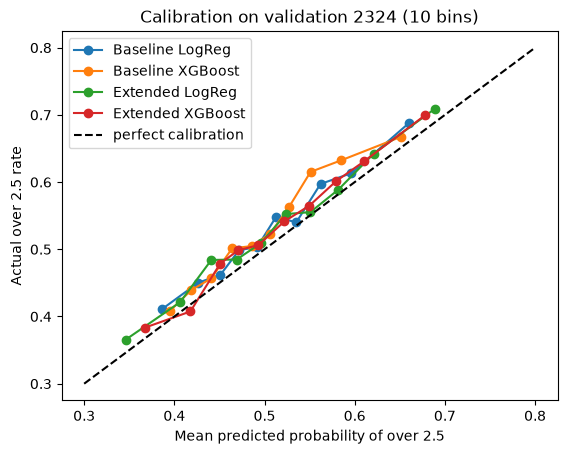

In [8]:
import matplotlib.pyplot as plt

# --- Section 8.1 checks on validation 2324 ---

# 1) Sanity: all probabilities are valid numbers strictly between 0 and 1
for name, probs in val_probs.items():
    assert not np.isnan(probs).any(), f"{name} produced NaN probabilities!"
    assert ((probs > 0) & (probs < 1)).all(), f"{name} probabilities out of (0, 1)!"
print("Sanity check passed: all validation probabilities are valid.")

# 2) Stability: compare our baseline predictions with Person A's exported ones
#    (same settings and data, but A ran them on a different machine)
a_preds = pd.read_csv("exports/baseline_val_predictions.csv")
diff_xgb = np.abs(a_preds["prob_baseline_xgb"].to_numpy() - p_base_xgb)
diff_lr = np.abs(a_preds["prob_baseline_logreg"].to_numpy() - p_base_lr)
flipped = ((a_preds["prob_baseline_xgb"].to_numpy() >= 0.5) != (p_base_xgb >= 0.5)).sum()

print(f"\nBaseline XGBoost vs Person A: max difference = {diff_xgb.max():.5f}, mean difference = {diff_xgb.mean():.5f}")
print(f"Baseline LogReg  vs Person A: max difference = {diff_lr.max():.2e}")
print(f"Matches with a different XGBoost over/under prediction: {flipped} of {len(a_preds)}")

# 3) Calibration: split matches into 10 equal groups by predicted probability
#    and compare the average predicted probability with the real over-rate in each group
calib_rows = []
for name, probs in val_probs.items():
    bins = pd.qcut(probs, 10, labels=False, duplicates="drop")
    calib = pd.DataFrame({"pred": probs, "actual": y_val.to_numpy(), "bin": bins}).groupby("bin").mean()
    calib_rows.append({
        "model": name,
        "max_gap": (calib["pred"] - calib["actual"]).abs().max(),     # worst group
        "mean_gap": (calib["pred"] - calib["actual"]).abs().mean(),   # average over the 10 groups
    })
    plt.plot(calib["pred"], calib["actual"], marker="o", label=name)

print("\nCalibration on validation 2324 (gap = |mean predicted - actual over-rate| per decile):")
display(pd.DataFrame(calib_rows).round(4))

# Calibration plot: a perfectly calibrated model lies on the dashed diagonal
plt.plot([0.3, 0.8], [0.3, 0.8], "k--", label="perfect calibration")
plt.xlabel("Mean predicted probability of over 2.5")
plt.ylabel("Actual over 2.5 rate")
plt.title("Calibration on validation 2324 (10 bins)")
plt.legend()
plt.show()

### Model checks on validation `2324` (Section 8.1)

**1. Sanity checks**
- All predicted probabilities of all 4 models are valid numbers strictly between `0` and `1` (no `NaN`), on both `2324` and `2425`.
- The feature list contains `88` features and no ID column or target (checked with an `assert` right after the split).

**2. Leakage checks**
- The split is strictly chronological: `split_by_season` asserts that all training dates are before validation and all validation dates are before test.
- All tuning (`C`, XGBoost grid, number of trees, feature ablation) used only train `2021–2223` and validation `2324`. The test season `2425` was used **once**, after every setting was frozen, and nothing was changed afterwards.
- The Extended XGBoost uses a **fixed** `n_estimators=348` in the final refit, so early stopping never sees `2425`.

**3. Stability checks**
- Our Baseline predictions are **identical** to Person A's exported predictions (max difference `0.00000`, `0` of `7,245` matches with a different over/under prediction), so the shared setup is reproduced exactly.
- Running the same code on a different machine (Google Colab, Linux) gave a slightly different Baseline XGBoost (`57.02%` / `0.67876` instead of `57.07%` / `0.67861`) and picked `279` instead of `348` trees for the Extended XGBoost with the same log-loss (`0.67373` vs `0.67372`). LogReg results were identical. This is caused by tiny floating-point differences between platforms, and the effect on the results is negligible. All reported results come from one run in one environment.
- Gain importances of correlated features are **not very stable**: `elo_diff` was rank `20` in the Colab run and rank `53` here. We therefore use the ablation test, not the importance ranking alone, to decide about features.

**4. Calibration** (matches split into 10 equal groups by predicted probability; gap = |mean predicted − actual over-rate| per group)

| Model | Max gap | Mean gap |
|---|---|---|
| Baseline LogReg | `3.6` pp | `2.2` pp |
| Baseline XGBoost | `6.4` pp | `2.9` pp |
| Extended LogReg | `4.3` pp | `1.9` pp |
| Extended XGBoost | `2.8` pp | `1.9` pp |

- The **Extended models are the best calibrated** (average gap below `2` pp), so their probabilities can be used directly for pricing in Section 7.
- The Baseline XGBoost is the worst calibrated, which matches its clear under-prediction of overs (`48.2%` vs `53.1%`).

**Resulting changes:** none of the checks required a change to the models or features. The only consequence is that all final numbers are taken from a single run of the notebook in one environment.

In [9]:
# ============================================================
# FINAL TEST RUN ON 2425 – all model settings and features are frozen above.
# This is the only cell that touches the test season. Do not retune after seeing these results!
# ============================================================

# Combine train and validation seasons (2021–2324), so the models also learn from 2324,
# the most recent normal-crowd season
train_val_ext = pd.concat([train_ext, val_ext])
print("Train + val matches:", len(train_val_ext))
assert len(train_val_ext) == 28973, "Unexpected number of train + val matches!"

y_train_val = train_val_ext[target]
y_test = test_ext[target]

# The 4 frozen models with the features each one uses
# (fixed n_estimators for both XGBoosts, no early stopping)
final_models = {
    "Baseline LogReg": (make_logreg_pipeline(C=BASELINE_LR_C), baseline_features),
    "Baseline XGBoost": (make_baseline_xgb(), baseline_features),
    "Extended LogReg": (make_logreg_pipeline(C=EXT_LR_C), all_features),
    "Extended XGBoost": (make_extended_xgb(), all_features),
}

# Refit each model on train + val and predict the test season
test_probs = {}
for name, (model, features) in final_models.items():
    model.fit(train_val_ext[features], y_train_val)
    test_probs[name] = model.predict_proba(test_ext[features])[:, 1]
    print(f"{name}: refitted on 2021–2324 and predicted 2425")

# Sanity check on the test probabilities
for name, probs in test_probs.items():
    assert not np.isnan(probs).any(), f"{name} produced NaN probabilities!"
    assert ((probs > 0) & (probs < 1)).all(), f"{name} probabilities out of (0, 1)!"

# --- Market reference on 2425 ---
print("\nMissing prob_over_avg values in 2425:", test_ext["prob_over_avg"].isna().sum())
test_market_pred = (test_ext["prob_over_avg"] > 0.5).astype(int)
test_market_correct = (test_market_pred == y_test)
test_market_acc = test_market_correct.mean()

# --- Overall comparison on 2425 ---
test_rows = []
test_country_acc = {}
for name, probs in test_probs.items():
    overall, by_country = evaluate_predictions(test_ext, probs, model_name=name)
    test_rows.append(overall)
    test_country_acc[name] = by_country.set_index("country")["accuracy"]

test_overall_df = pd.DataFrame(test_rows)[["model", "accuracy", "log_loss", "pred_over_rate"]]
test_overall_df["vs_market_pp"] = (test_overall_df["accuracy"] - test_market_acc) * 100
test_market_row = {"model": "Market (prob_over_avg > 0.5)", "accuracy": test_market_acc,
                   "log_loss": np.nan, "pred_over_rate": test_market_pred.mean(), "vs_market_pp": 0.0}
test_overall_df = pd.concat([test_overall_df, pd.DataFrame([test_market_row])], ignore_index=True)

print(f"\nFINAL TEST RESULTS 2425 (market accuracy = {test_market_acc:.4f}, true over-rate = {y_test.mean():.4f}):")
display(test_overall_df.round(5))

# --- Per-country accuracy on 2425 ---
test_country_df = pd.DataFrame(test_country_acc)
test_country_df["Market"] = test_market_correct.groupby(test_ext["country"]).mean()
test_country_df["matches"] = test_ext.groupby("country").size()
test_country_df = test_country_df.sort_values("matches", ascending=False)

print("\nAccuracy per country on test 2425:")
display(test_country_df.round(4))

for name in test_probs:
    n_better = (test_country_df[name] > test_country_df["Market"]).sum()
    print(f"{name}: beats the market in {n_better} of {len(test_country_df)} countries")

Train + val matches: 28973
Baseline LogReg: refitted on 2021–2324 and predicted 2425
Baseline XGBoost: refitted on 2021–2324 and predicted 2425
Extended LogReg: refitted on 2021–2324 and predicted 2425
Extended XGBoost: refitted on 2021–2324 and predicted 2425

Missing prob_over_avg values in 2425: 0

FINAL TEST RESULTS 2425 (market accuracy = 0.5716, true over-rate = 0.5069):


,model,accuracy,log_loss,pred_over_rate,vs_market_pp
0,Baseline LogReg,0.54799,0.68410,0.53873,-2.35756
1,Baseline XGBoost,0.55473,0.68405,0.51740,-1.68397
2,Extended LogReg,0.56918,0.67839,0.49060,-0.23856
3,Extended XGBoost,0.56946,0.67813,0.47348,-0.21050
4,Market (prob_over_avg > 0.5),0.57157,NaN,0.48709,0.00000



Accuracy per country on test 2425:


,Baseline LogReg,Baseline XGBoost,Extended LogReg,Extended XGBoost,Market,matches
country,,,,,,
england,0.5457,0.5457,0.5521,0.5570,0.5683,2036
spain,0.5558,0.5499,0.5879,0.5760,0.5819,842
scotland,0.5378,0.5430,0.5195,0.5417,0.5312,768
italy,0.5211,0.5421,0.5618,0.5632,0.5566,760
france,0.5474,0.5588,0.5768,0.5752,0.5899,612
germany,0.5876,0.5990,0.6399,0.6137,0.6137,611
turkey,0.5484,0.5689,0.5806,0.5777,0.5572,341
belgium,0.5756,0.5723,0.5852,0.5916,0.5884,311
netherlands,0.5654,0.5686,0.5784,0.5752,0.5784,306


Baseline LogReg: beats the market in 1 of 11 countries
Baseline XGBoost: beats the market in 2 of 11 countries
Extended LogReg: beats the market in 5 of 11 countries
Extended XGBoost: beats the market in 5 of 11 countries


### Final test results on `2425`

All 4 frozen models were refitted on train + validation (`2021–2324`, `28,973` matches) and evaluated **once** on the untouched test season `2425` (`7,126` matches).

| Model | Accuracy | Log-loss | Predicted over-rate | vs market (pp) |
|---|---|---|---|---|
| Baseline LogReg | `54.80%` | `0.68410` | `53.9%` | `-2.36` |
| Baseline XGBoost | `55.47%` | `0.68405` | `51.7%` | `-1.68` |
| Extended LogReg | `56.92%` | `0.67839` | `49.1%` | `-0.24` |
| **Extended XGBoost** | **`56.95%`** | **`0.67813`** | `47.3%` | `-0.21` |
| Market (`prob_over_avg > 0.5`) | `57.16%` | – | `48.7%` | `0.00` |

True over-rate in `2425`: `50.7%` (vs `53.1%` in `2324`)

**Observations:**
- **No model beats the market on the test season.** The Extended models are only `0.2` pp below it (about `15–17` matches out of `7,126`), which is within noise, so they are roughly **as good as the market**, but not better.
- The small advantage over the market on `2324` (`+0.35` to `+0.50` pp) **did not hold**. This fits the expectation that validation scores are slightly optimistic (the settings were tuned on `2324`) and that the betting market is hard to beat.
- The **extended features clearly help**: both Extended models are `1.5–2` pp more accurate than the Baseline models and have a clearly lower log-loss (`~0.678` vs `~0.684`).
- On `2425`, the **Extended XGBoost** is slightly better than the Extended LogReg (log-loss `0.67813` vs `0.67839`), the opposite of `2324`. The two models are practically equal.
- **All models scored lower than on `2324`.** Part of this is the season itself: the over-rate dropped from `53.1%` to `50.7%`, so `2425` was a lower-scoring season. The Baseline LogReg kept predicting too many overs (`53.9%`), which costs it the most.

**Per country:** both Extended models beat the market in `5` of `11` countries (Extended XGBoost: Scotland, Italy, Turkey, Belgium, Portugal; Extended LogReg: Spain, Italy, Germany, Turkey, Portugal). The Baseline models beat it in only `1–2` countries. As on validation, single-country differences of a few pp are within noise.

In [10]:
# --- Export per-match predictions of all 4 models for Person C ---
# Column names follow Person A's file (prob_baseline_xgb, prob_baseline_logreg) plus the two extended models
# Validation 2324: models trained on 2021–2223 | Test 2425: models trained on 2021–2324
column_names = {
    "Baseline XGBoost": "prob_baseline_xgb",
    "Baseline LogReg": "prob_baseline_logreg",
    "Extended XGBoost": "prob_extended_xgb",
    "Extended LogReg": "prob_extended_logreg",
}

val_preds = build_predictions_df(val_ext, {col: val_probs[name] for name, col in column_names.items()})
test_preds = build_predictions_df(test_ext, {col: test_probs[name] for name, col in column_names.items()})

# exports/ is git-ignored, so these files are never committed – send them to Person C directly
val_preds.to_csv("exports/val_predictions_2324.csv", index=False)
test_preds.to_csv("exports/test_predictions_2425.csv", index=False)

print(f"Saved {len(val_preds)} validation predictions to exports/val_predictions_2324.csv")
print(f"Saved {len(test_preds)} test predictions to exports/test_predictions_2425.csv")
print("Countries in test file:", test_preds["country"].nunique())
display(test_preds.head())

Saved 7245 validation predictions to exports/val_predictions_2324.csv
Saved 7126 test predictions to exports/test_predictions_2425.csv
Countries in test file: 11


,country,season,Date,HomeTeam,AwayTeam,over_2_5,prob_baseline_xgb,prob_baseline_logreg,prob_extended_xgb,prob_extended_logreg
1458,belgium,2425,2024-07-27,Anderlecht,St Truiden,0,0.533459,0.548229,0.591981,0.620917
1459,belgium,2425,2024-07-27,Beerschot VA,Oud-Heverlee Leuven,0,0.506661,0.501462,0.514824,0.488384
1460,belgium,2425,2024-07-28,Charleroi,Antwerp,0,0.476383,0.476771,0.536020,0.562294
1461,belgium,2425,2024-07-26,Club Brugge,Mechelen,0,0.608047,0.608510,0.599935,0.597658
1462,belgium,2425,2024-07-27,Dender,St. Gilloise,0,0.501383,0.538539,0.536481,0.584970
